# 9.2 Wage gap

**Issue #09, Pillar 3 (Who Actually Gets Paid).**

Notebook 9.1 showed where the sewing job went. This one asks what the job pays, in the US and in Bangladesh, and sets both against the price one famous pair of jeans fetched at auction.

Every figure here is entered by hand from a named source. Nothing is pulled live. Each input carries its source and the date it was checked, and the same details are logged in `sources/cycle 2/issue-09/sources.md`.

**Questions this notebook answers**

1. How long does a US sewing machine operator work to earn one month of Bangladesh's legal minimum for garment workers?
2. How many years of sewing pay, in each country, equal the auction price of one pair of jeans?

**What it does not answer:** Whether either wage is fair, or what a worker can afford on it. Living costs differ between the two countries and this notebook does not adjust for them.

## 1. Setup

Imports and file paths. No API key is needed because nothing is fetched.

This notebook sits three folders deep (`notebooks/cycle 2/issue-09/`), so paths back to the repo root start with `../../../`.

In [1]:
from pathlib import Path       # build file paths that work on Windows and Mac

import pandas as pd            # tables
import matplotlib.pyplot as plt

# Repo root, relative to this notebook's folder.
ROOT = Path("../../..")
PROCESSED_DIR = ROOT / "data" / "processed" / "cycle 2" / "issue-09"   # committed

# Create the folder if notebook 09.1 has not already done so.
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 2. Extracting and analyzing data

### 2.1 Manual inputs

Each number below was read from its source by hand. The comment beside it says where it came from and when it was checked.

Notes on what each input means:

- **Bangladesh minimum:** The legal monthly floor for the lowest garment-worker grade, set in December 2023 and kept in taka, its original currency. It excludes overtime and any yearly increment, so actual take-home pay can be higher.
- **Exchange rate:** Written as taka per one US dollar. Logged with its date because the rate moves.
- **US sewing pay:** The median hourly wage for sewing machine operators working in clothing manufacturing. Median means half earn more and half earn less. It is not a legal minimum, so the two wage figures are not like for like.
- **Auction price:** The reported sale price of one pair of jeans worn in a 1954 film, sold in 2025.

In [ ]:
# --- Bangladesh --------------------------------------------------------------
# Legal monthly minimum for entry-grade garment workers, in taka.
# Source: Reuters, 8 Nov 2023. In force from 1 Dec 2023. Unchanged as of Aug 2026.
BD_MIN_MONTHLY_BDT = 12_500

# Exchange rate: taka per 1 US dollar.
# Source: exchange-rates.org, 8 Oct 2026 (20:00 UTC). Re-check on publish day.
BDT_PER_USD = 123.17
RATE_DATE = "2026-10-08"

# Rate when the minimum was announced, as reported at the time (about US$114).
# Used only to show how much the dollar value moved through currency alone.
BD_MIN_USD_AT_ANNOUNCEMENT = 114

# --- United States -----------------------------------------------------------
# Median hourly wage, sewing machine operators (occupation code 51-6031),
# in apparel manufacturing (industry code 315000).
# Source: U.S. Bureau of Labor Statistics, Occupational Employment and Wage
# Statistics, May 2025 tables. ENTER THE VALUE BY HAND from the BLS table.
US_SEWING_HOURLY_USD = 17.37

# Hours in a full-time working year. This is the convention BLS itself uses
# to turn an hourly wage into an annual one (40 hours x 52 weeks).
HOURS_PER_YEAR = 2080

# --- The jeans ---------------------------------------------------------------
# Sources: Andaloro, A., People, 17 April 2025, and The Marilyn Report,
# updated 27 March 2025. Sale held 27 March 2025.
# Auction house's own pre-sale estimate was US$30,000 to US$50,000.
AUCTION_PRICE_USD = 52_000

# --- Facts logged for the record (no calculation) ----------------------------
US_PLANTS_EARLY_1980S = 63    # one jeans maker's US plants. Source: AP, Jan 2004.
US_PLANTS_AFTER_2004 = 0      # last US sewing plants closed Jan 2004. Source: company release, Sept 2003.
IMPORT_SHARE_PCT = 97         # share of US clothing that is imported. Source: trade association, approximate.

### 2.2 Convert taka to US dollars

The Bangladesh figure is kept in taka and converted with a function whose name states the direction, so the rate cannot be applied the wrong way round.

The rate is "taka per one dollar," so going from taka to dollars means **dividing** by it.

In [4]:
def bdt_to_usd(amount_bdt, bdt_per_usd):
    return amount_bdt / bdt_per_usd


# Monthly and yearly Bangladesh minimum in dollars, at the logged rate.
bd_month_usd = bdt_to_usd(BD_MIN_MONTHLY_BDT, BDT_PER_USD)
bd_year_usd = bd_month_usd * 12

# US sewing pay for a full-time year.
us_year_usd = US_SEWING_HOURLY_USD * HOURS_PER_YEAR

print(f"Bangladesh minimum: {BD_MIN_MONTHLY_BDT:,} taka a month")
print(f"  = US${bd_month_usd:,.2f} a month at {BDT_PER_USD} taka per dollar ({RATE_DATE})")
print(f"  = US${bd_year_usd:,.0f} a year")
print(f"US sewing machine operator: US${US_SEWING_HOURLY_USD:,.2f} an hour, US${us_year_usd:,.0f} a full-time year")

Bangladesh minimum: 12,500 taka a month
  = US$101.49 a month at 123.17 taka per dollar (2026-10-08)
  = US$1,218 a year
US sewing machine operator: US$17.37 an hour, US$36,130 a full-time year


### 2.3 Headline numbers

Three comparisons, all in the same unit so they can be read directly.

1. **Hours to earn a month:** How many hours a US sewing machine operator works to earn one month of the Bangladesh minimum. This avoids guessing how many hours a Bangladeshi worker puts in.
2. **Years to earn the jeans:** How many full years of pay, in each country, equal the auction price.
3. **Currency drift:** How much the dollar value of the Bangladesh minimum changed since it was announced, purely because the exchange rate moved. The taka amount itself did not change.

In [5]:
# 1. Hours of US sewing work to earn one month of the Bangladesh minimum.
hours_for_bd_month = bd_month_usd / US_SEWING_HOURLY_USD
workdays_for_bd_month = hours_for_bd_month / 8   # in 8-hour working days

# How many times larger the US yearly figure is. Shown for reference only:
# it compares a median with a legal floor, so it is not a like-for-like ratio.
us_to_bd_multiple = us_year_usd / bd_year_usd

# 2. Years of pay equal to the auction price.
years_us = AUCTION_PRICE_USD / us_year_usd
years_bd = AUCTION_PRICE_USD / bd_year_usd

# 3. Change in the dollar value of the minimum since it was announced.
currency_drift_pct = (bd_month_usd / BD_MIN_USD_AT_ANNOUNCEMENT - 1) * 100

print(f"Hours of US sewing work to earn one Bangladesh monthly minimum: {hours_for_bd_month:.1f}")
print(f"  = about {workdays_for_bd_month:.1f} eight-hour working days")
print(f"US full-time year vs. Bangladesh minimum year: about {us_to_bd_multiple:.0f}x (not like for like)")
print(f"Years of US sewing pay to equal the auction price:        {years_us:.1f}")
print(f"Years of Bangladesh minimum pay to equal the auction price: {years_bd:.1f}")
print(f"Dollar value of the minimum since announcement: {currency_drift_pct:+.1f}% (exchange rate only)")

Hours of US sewing work to earn one Bangladesh monthly minimum: 5.8
  = about 0.7 eight-hour working days
US full-time year vs. Bangladesh minimum year: about 30x (not like for like)
Years of US sewing pay to equal the auction price:        1.4
Years of Bangladesh minimum pay to equal the auction price: 42.7
Dollar value of the minimum since announcement: -11.0% (exchange rate only)


### 2.4 Save inputs and results

Two small tables are saved so every published number can be traced: the inputs as entered, and the results calculated from them. The results table is also what gets typed into Canva.

In [7]:
# Inputs, exactly as entered above.
inputs = pd.DataFrame(
    [
        ("Bangladesh garment minimum, monthly", BD_MIN_MONTHLY_BDT, "BDT"),
        ("Exchange rate, taka per US dollar", BDT_PER_USD, RATE_DATE),
        ("US sewing machine operator, median hourly", US_SEWING_HOURLY_USD, "USD"),
        ("Hours in a full-time year", HOURS_PER_YEAR, "hours"),
        ("Auction price, one pair of jeans", AUCTION_PRICE_USD, "USD"),
        ("One jeans maker's US plants, early 1980s", US_PLANTS_EARLY_1980S, "plants"),
        ("Same jeans maker's US plants, after Jan 2004", US_PLANTS_AFTER_2004, "plants"),
        ("Share of US clothing imported, approximate", IMPORT_SHARE_PCT, "percent"),
    ],
    columns=["input", "value", "unit_or_date"],
)

# Results, rounded for reading.
results = pd.DataFrame(
    [
        ("Bangladesh minimum, monthly", round(bd_month_usd, 2), "USD"),
        ("Bangladesh minimum, yearly", round(bd_year_usd), "USD"),
        ("US sewing machine operator, yearly", round(us_year_usd), "USD"),
        ("US sewing hours to earn one Bangladesh month", round(hours_for_bd_month, 1), "hours"),
        ("Years of US sewing pay to equal auction price", round(years_us, 1), "years"),
        ("Years of Bangladesh minimum to equal auction price", round(years_bd, 1), "years"),
    ],
    columns=["result", "value", "unit"],
)

inputs.to_csv(PROCESSED_DIR / "9.2_inputs.csv", index=False)
results.to_csv(PROCESSED_DIR / "9.2_results.csv", index=False)

results

,result,value,unit
0,"Bangladesh minimum, monthly",101.49,USD
1,"Bangladesh minimum, yearly",1218.00,USD
2,"US sewing machine operator, yearly",36130.00,USD
3,US sewing hours to earn one Bangladesh month,5.80,hours
4,Years of US sewing pay to equal auction price,1.40,years
5,Years of Bangladesh minimum to equal auction p...,42.70,years


## 3. Plot

One exploratory chart, for reading the size of the gap. The published version is built in Canva from the results table in 2.4, then checked against this one.

The bars show how many full years of pay equal the auction price of the jeans.

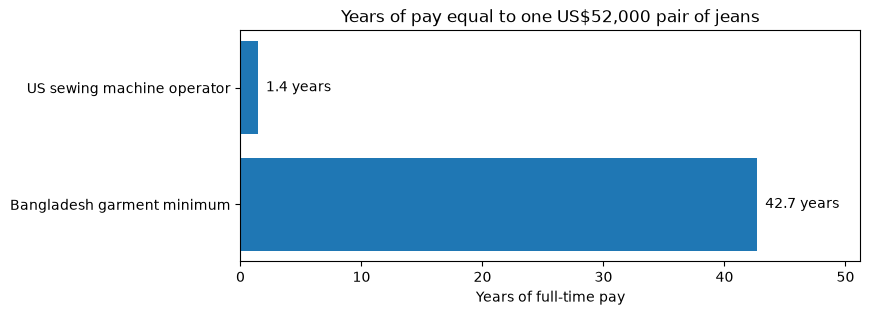

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))

labels = ["Bangladesh garment minimum", "US sewing machine operator"]
years = [years_bd, years_us]

ax.barh(labels, years)

# Write the value at the end of each bar.
for y, value in enumerate(years):
    ax.text(value, y, f"  {value:.1f} years", va="center")

ax.set_title(f"Years of pay equal to one US${AUCTION_PRICE_USD:,} pair of jeans")
ax.set_xlabel("Years of full-time pay")
ax.set_xlim(0, max(years) * 1.2)   # room for the labels
plt.show()

## 4. Findings

**Headline numbers**

- Bangladesh garment minimum: 12,500 taka a month, about US$101.49 at 123.17 taka per dollar (8 October 2026). About US$1,218 a year.
- US sewing machine operator: US$17.37 an hour (median, May 2025), about US$36,130 for a full-time year.
- A US sewing machine operator earns one month of the Bangladesh minimum in about 5.8 hours, less than one eight-hour working day.
- The auction price of one pair of jeans (US$52,000) equals about 1.4 years of US sewing pay, or about 42.7 years of the Bangladesh minimum.
- The auction house's own pre-sale estimate was US$30,000 to US$50,000, equal to about 25 to 41 years of the Bangladesh minimum. The conclusion holds across that range.
- A US full-time year is about 30 times a year at the Bangladesh minimum. This compares a median with a legal floor, so it is a sense of scale only.
- The dollar value of the Bangladesh minimum is about 11% lower than when it was announced (about US$114 then), through the exchange rate alone. The taka amount has not changed.

**What this does and does not show**

- It shows the size of the pay gap for the same kind of work in two places.
- It compares a US median with a Bangladeshi legal minimum. These are different kinds of figure, so the gap is a sense of scale, not a precise ratio.
- It does not adjust for living costs, which are far lower in Bangladesh.
- The Bangladesh figure excludes overtime and yearly increments, so real earnings can be higher.
- An auction price reflects who wore the jeans, not what the jeans are worth as clothing. It is used for scale only.
- Garment work is a major source of income for millions of people in Bangladesh, most of them women. A low wage by US standards is not the same as a job nobody wants.
- About 25,280 people work as sewing machine operators in US apparel manufacturing (May 2025), roughly a third of the industry's remaining jobs. The two counts come from different surveys.

**Chart**

- The bar chart in section 3 is exploratory. The published version is built in Canva from the results table in 2.4, with "typical pay" and "at the legal minimum" written on the slide.

**Does the pre-analysis thesis hold?**

Yes. The job that left the US now pays, at the legal minimum, a small fraction of what it pays in the US. The US wage itself is modest, so this is not a story of a well-paid job lost.

**Sources**

- Paul, R., & Jamkhandikar, S. (2023, November 8). Bangladesh hikes minimum wage for garment workers after protests. *Reuters*.
- U.S. Bureau of Labor Statistics. (2026). *Occupational Employment and Wage Statistics, May 2025: Sewing machine operators (51-6031) in apparel manufacturing (315000)*.
- Exchange rate from exchange-rates.org, 8 October 2026.
- Auction result as reported by People, April 2025. Sale held 27 March 2025.
- Plant closure: company press release, September 2003, and Associated Press, January 2004. Company name held in `sources.md` as internal reference